# 03 · Modelo de scoring — Sprint 2 (F3)
> **Datos 100 % sintéticos.** AURORA SCORE y Vertex Financial Group son un caso ficticio con fines académicos (SCY1102, Duoc UC). Ejecutar antes `python src/pipeline.py`.

Tarjetas AUR-10, AUR-11, AUR-12. LightGBM con split temporal: entrena con enero a septiembre de 2025 y evalúa con octubre a diciembre.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
REP = RAIZ / "reports"; FIG = REP / "figures"
leer = lambda n: json.loads((REP / n).read_text(encoding="utf-8"))

In [2]:
m = leer('metricas_modelos.json')
print('Train:', m['periodo_train'], m['n_train'], '· Test:', m['periodo_test'], m['n_test'])
cols = ['etiqueta_entrenamiento','auc_train','auc_test_real','ks_test_real','auc_test_registrada','tasa_aprobacion','mora_aprobados','mora_rechazados']
pd.DataFrame({k: {c: v[c] for c in cols} for k, v in m['modelos'].items()})

Train: ['2025-01-01', '2025-09-29'] 30000 · Test: ['2025-10-01', '2025-12-30'] 12000


,v1-base,v2-mitigado
etiqueta_entrenamiento,incumplio_registrado,incumplio
auc_train,0.8259,0.8378
auc_test_real,0.7448,0.8085
ks_test_real,0.3327,0.4782
auc_test_registrada,0.7684,0.7133
tasa_aprobacion,0.4435,0.7476
mora_aprobados,0.0419,0.0524
mora_rechazados,0.1661,0.2846


## Matriz de confusión al umbral por país (positivo = rechazo)

In [3]:
pd.DataFrame({k: v['matriz_confusion'] for k, v in m['modelos'].items()})

,v1-base,v2-mitigado
rechaza_y_incumple,1109,862
rechaza_y_paga,5569,2167
aprueba_e_incumple,223,470
aprueba_y_paga,5099,8501


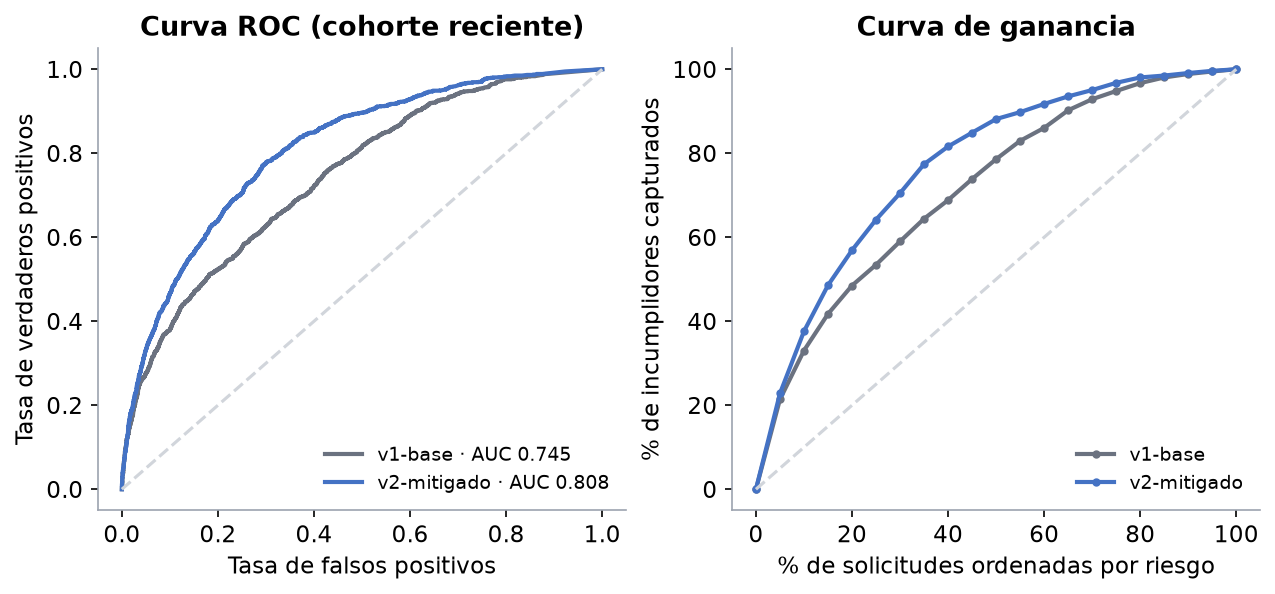

In [4]:
display(Image(FIG / '03_roc_ganancia.png', width=900))

## Registro de modelos (hash, fecha y variables)

In [5]:
reg = json.loads((RAIZ / 'models/registro_modelos.json').read_text(encoding='utf-8'))
pd.DataFrame({k: {'sha256': v['sha256'][:20] + '…', 'fecha': v['fecha_entrenamiento'], 'n_variables': v['n_variables'], 'corte': v['corte']} for k, v in reg.items()})

,v1-base,v2-mitigado
sha256,024dd5243c8946ce4125…,3d3fe1b192eeb225bd78…
fecha,2026-11-25T14:18:12,2026-11-25T14:18:12
n_variables,42,43
corte,2025-09-30,2025-09-30


## Motor de decisión: umbrales por país desde `params.yaml`

In [6]:
from decision import MotorDecision
from train import cargar
df = cargar(); te = df[df.cohorte == 'reciente']
motor = MotorDecision()
dec = motor.decidir(te, te.pais)
dec.assign(pais=te.pais.values).groupby('pais').agg(umbral=('umbral', 'first'), aprobacion=('aprobado', 'mean'), pd_media=('pd', 'mean')).round(3)

,umbral,aprobacion,pd_media
pais,,,
CL,0.13,0.755,0.107
CO,0.12,0.726,0.107
MX,0.12,0.739,0.104
PE,0.13,0.758,0.105


In [7]:
pd.read_csv(REP / 'importancia_v2.csv').head(10)

,variable,importancia_gain
0,atraso_servicios_medio_conc,32359.314301
1,pct_pagos_tardios_5d_conc,9566.504664
2,pct_pagos_tardios_conc,6982.180008
3,recargas_media,2256.553614
4,atraso_postpago_medio,1314.972778
5,monto_recargas_medio,1294.169059
6,atraso_servicios_max_conc,1241.474940
7,tiempo_pantallas_seg,1158.149698
8,monto_recargas_tendencia,1080.991244
9,cuota_sobre_recarga,1000.470581
